In [7]:
# Installation et imports
!pip install -q kagglehub opencv-python-headless scikit-learn tensorflow matplotlib pandas numpy

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


In [11]:
# Téléchargement du dataset ACRIMA
import kagglehub

# Téléchargement automatique du dataset ACRIMA via kagglehub
DATA_DIR = kagglehub.dataset_download("orvile/acrima-glaucoma-assessment-using-fundus-images")
print("Chemin des fichiers du dataset :", DATA_DIR)

# Inspection de l'arborescence
for root, dirs, fnames in os.walk(DATA_DIR):
    n_images = sum(1 for f in fnames if f.lower().endswith((".png", ".jpg", ".jpeg")))
    if n_images > 0:
        print(f"{root} -> {n_images} images")

Using Colab cache for faster access to the 'acrima-glaucoma-assessment-using-fundus-images' dataset.
Chemin des fichiers du dataset : /kaggle/input/acrima-glaucoma-assessment-using-fundus-images
/kaggle/input/acrima-glaucoma-assessment-using-fundus-images/Database/Images -> 705 images


In [19]:
#Construction et Vérification du DataFrame
def build_dataframe(data_dir):
    records = []
    for root, dirs, fnames in os.walk(data_dir):
        for f in fnames:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                full_path = os.path.join(root, f)

                # On analyse uniquement le NOM du fichier
                filename = f.lower()

                # Si le nom contient '_g_', c'est un glaucome (1), sinon c'est sain (0)
                if "_g_" in filename:
                    label = 1
                else:
                    label = 0

                records.append({"path": full_path, "label": label})

    return pd.DataFrame(records)

# Exécution
df = build_dataframe(DATA_DIR)

print("Nombre total d'images :", len(df))
print(df["label"].value_counts().rename({0: "Sain (0)", 1: "Glaucome (1)"}))

Nombre total d'images : 705
label
Glaucome (1)    396
Sain (0)        309
Name: count, dtype: int64


In [21]:
#Division des Données (Train / Val / Test)
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 493 | Val: 106 | Test: 106


In [22]:
# Fonctions de Prétraitement des Images
def load_raw(path):
    """Pipeline minimal : lecture RGB + resize."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img.astype(np.float32)

def load_preprocessed(path):
    """Pipeline avec rehaussement CLAHE sur le canal L + Crop central."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    img_eq = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2RGB)

    h, w, _ = img_eq.shape
    crop_ratio = 0.9
    ch, cw = int(h * crop_ratio), int(w * crop_ratio)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    img_eq = img_eq[y0:y0 + ch, x0:x0 + cw]

    img_eq = cv2.resize(img_eq, (IMG_SIZE, IMG_SIZE))
    return img_eq.astype(np.float32)

def build_arrays(df_input, loader_fn):
    X, y = [], []
    for _, row in df_input.iterrows():
        X.append(loader_fn(row["path"]))
        y.append(row["label"])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

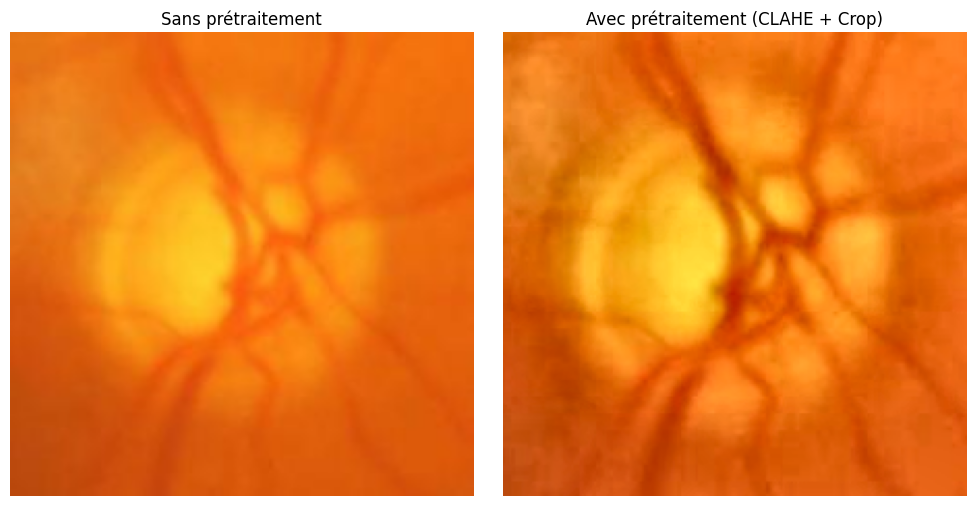

In [23]:
#Visualisation Comparative d'un Échantillon
sample_path = df.iloc[0]["path"]
raw_sample = load_raw(sample_path).astype(np.uint8)
prep_sample = load_preprocessed(sample_path).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(raw_sample)
axes[0].set_title("Sans prétraitement")
axes[0].axis("off")
axes[1].imshow(prep_sample)
axes[1].set_title("Avec prétraitement (CLAHE + Crop)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [24]:
# Chargement des Tableaux pour les Deux Pipelines
print("Chargement pipeline SANS prétraitement...")
X_train_raw, y_train = build_arrays(train_df, load_raw)
X_val_raw, y_val = build_arrays(val_df, load_raw)
X_test_raw, y_test = build_arrays(test_df, load_raw)

print("Chargement pipeline AVEC prétraitement...")
X_train_prep, _ = build_arrays(train_df, load_preprocessed)
X_val_prep, _ = build_arrays(val_df, load_preprocessed)
X_test_prep, _ = build_arrays(test_df, load_preprocessed)

print("Chargement des données terminé !")

Chargement pipeline SANS prétraitement...
Chargement pipeline AVEC prétraitement...
Chargement des données terminé !


In [25]:
#Calcul des Poids de Classes
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes.tolist(), weights.tolist()))
print("Poids de classes :", class_weight_dict)

Poids de classes : {0: 1.1412037037037037, 1: 0.8898916967509025}


In [26]:
# Architecture ResNet50 et Entraînement
def build_resnet50_model(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = layers.Lambda(preprocess_input)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )
    return model

def train_model(X_tr, y_tr, X_v, y_v):
    model = build_resnet50_model()
    es = callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True
    )
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_v, y_v),
        epochs=20,
        batch_size=16,
        class_weight=class_weight_dict,
        callbacks=[es],
        verbose=1,
    )
    return model, history

print("\n=== Entraînement SANS prétraitement ===")
model_raw, hist_raw = train_model(X_train_raw, y_train, X_val_raw, y_val)

print("\n=== Entraînement AVEC prétraitement ===")
model_prep, hist_prep = train_model(X_train_prep, y_train, X_val_prep, y_val)



=== Entraînement SANS prétraitement ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 33s 583ms/step - accuracy: 0.5416 - auc: 0.5985 - loss: 0.8127 - precision: 0.6032 - recall: 0.5379 - val_accuracy: 0.7830 - val_auc: 0.8690 - val_loss: 0.4706 - val_precision: 0.7761 - val_recall: 0.8667
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - accuracy: 0.7018 - auc: 0.7648 - loss: 0.6077 - precision: 0.7539 - recall: 0.6968 - val_accuracy: 0.8302 - val_auc: 0.9203 - val_loss: 0.3739 - val_precision: 0.8281 - val_recall: 0.8833
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.7748 - auc: 0.8429 - loss: 0.4940 - precision: 0.8192 - recall: 0.7690 - val_accuracy: 0.8208 - val_auc: 0.9447 - val_loss: 0.3350 - val_precision: 0.7733 - val_recall: 0.9667
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.7890 - auc: 0.8799 - loss: 0.4369 - precision: 0.8145 - recall: 0.8087 - val_accuracy: 0.8679 - val_auc: 0.9591 - val_

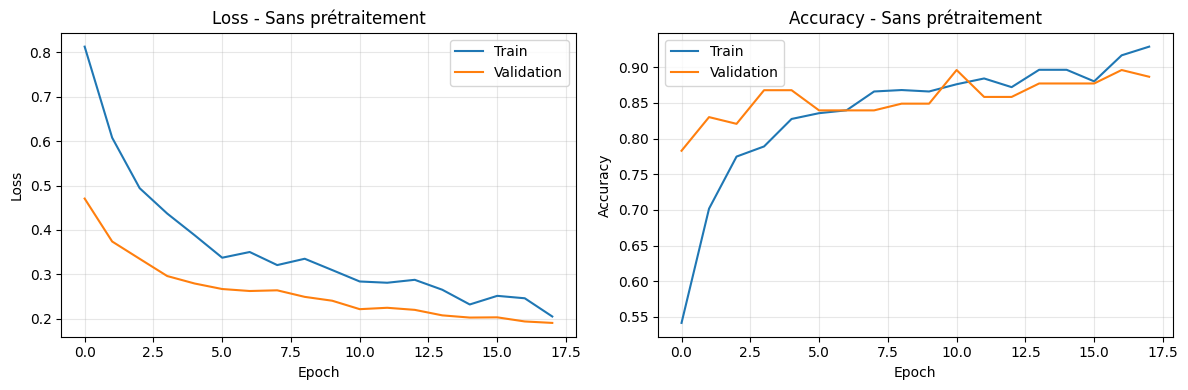

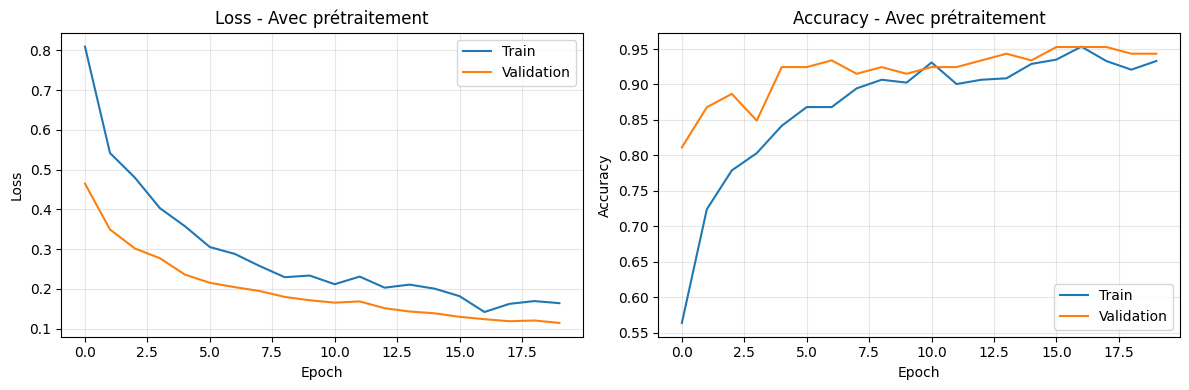

In [27]:
#Courbes d'Apprentissage
def plot_learning_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    axes[0].plot(history.history["loss"], label="Train")
    axes[0].plot(history.history["val_loss"], label="Validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(history.history["accuracy"], label="Train")
    axes[1].plot(history.history["val_accuracy"], label="Validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_learning_curves(hist_raw, "Sans prétraitement")
plot_learning_curves(hist_prep, "Avec prétraitement")

In [28]:
# Évaluation des Performances Médicales
def evaluate_model(model, X_test_data, y_test_data, name):
    y_prob = model.predict(X_test_data).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_test_data, y_pred)
    sens = recall_score(y_test_data, y_pred)
    prec = precision_score(y_test_data, y_pred)
    f1 = f1_score(y_test_data, y_pred)
    auc = roc_auc_score(y_test_data, y_prob)

    tn, fp, fn, tp = confusion_matrix(y_test_data, y_pred).ravel()
    spec = tn / (tn + fp)

    print(f"\n--- {name} ---")
    print(f"Accuracy    : {acc:.4f}")
    print(f"Sensibilité : {sens:.4f}")
    print(f"Spécificité : {spec:.4f}")
    print(f"Précision   : {prec:.4f}")
    print(f"F1-score    : {f1:.4f}")
    print(f"ROC-AUC     : {auc:.4f}")

    return {
        "name": name, "y_prob": y_prob, "y_pred": y_pred,
        "acc": acc, "sens": sens, "spec": spec, "prec": prec, "f1": f1, "auc": auc,
    }

res_raw = evaluate_model(model_raw, X_test_raw, y_test, "Sans prétraitement")
res_prep = evaluate_model(model_prep, X_test_prep, y_test, "Avec prétraitement")

4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step

--- Sans prétraitement ---
Accuracy    : 0.9245
Sensibilité : 0.9661
Spécificité : 0.8723
Précision   : 0.9048
F1-score    : 0.9344
ROC-AUC     : 0.9906
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step

--- Avec prétraitement ---
Accuracy    : 0.9811
Sensibilité : 0.9831
Spécificité : 0.9787
Précision   : 0.9831
F1-score    : 0.9831
ROC-AUC     : 0.9960


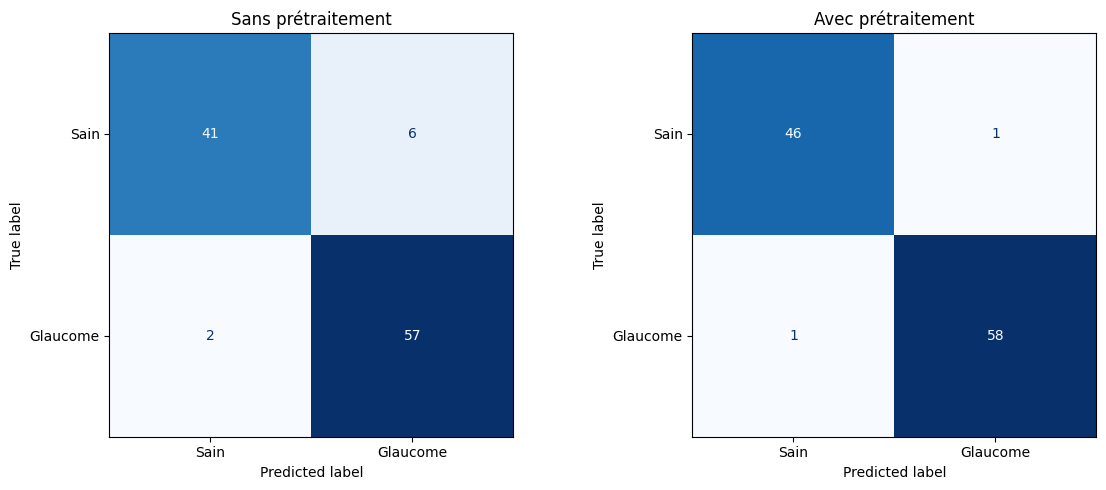

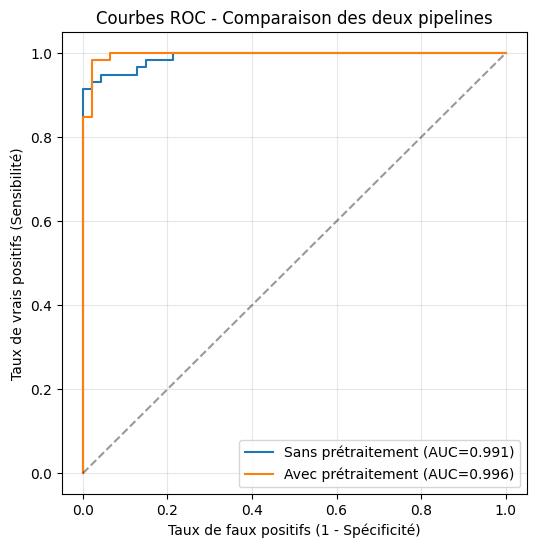

          Pipeline  Accuracy  Sensibilité  Spécificité  Précision       F1  ROC-AUC
Sans prétraitement  0.924528     0.966102     0.872340   0.904762 0.934426 0.990624
Avec prétraitement  0.981132     0.983051     0.978723   0.983051 0.983051 0.996033


In [29]:
#Visualisations (Matrices de Confusion & Courbes ROC)
# Matrices de confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, res_raw["y_pred"]), display_labels=["Sain", "Glaucome"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Sans prétraitement")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, res_prep["y_pred"]), display_labels=["Sain", "Glaucome"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Avec prétraitement")
plt.tight_layout()
plt.show()

# Courbes ROC
fpr_raw, tpr_raw, _ = roc_curve(y_test, res_raw["y_prob"])
fpr_prep, tpr_prep, _ = roc_curve(y_test, res_prep["y_prob"])

plt.figure(figsize=(6, 6))
plt.plot(fpr_raw, tpr_raw, label=f"Sans prétraitement (AUC={res_raw['auc']:.3f})")
plt.plot(fpr_prep, tpr_prep, label=f"Avec prétraitement (AUC={res_prep['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.title("Courbes ROC - Comparaison des deux pipelines")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Tableau récapitulatif
comparison_df = pd.DataFrame([res_raw, res_prep])[
    ["name", "acc", "sens", "spec", "prec", "f1", "auc"]
]
comparison_df.columns = [
    "Pipeline", "Accuracy", "Sensibilité", "Spécificité", "Précision", "F1", "ROC-AUC"
]
print(comparison_df.to_string(index=False))

Veuillez uploader une image de fond d'œil (fundus) :


Saving my_eye_image_1.jpeg to my_eye_image_1.jpeg


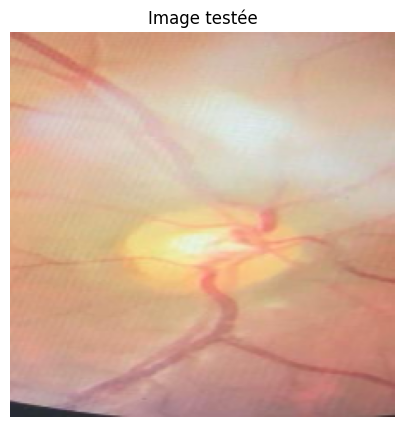


--- Modèle sans prétraitement ---
Probabilité de glaucome : 0.1598
Prédiction : Sain

--- Modèle avec prétraitement ---
Probabilité de glaucome : 0.0129
Prédiction : Sain


In [30]:
# Test sur une image externe
from google.colab import files

print("Veuillez uploader une image de fond d'œil (fundus) :")
uploaded_image = files.upload()

if uploaded_image:
    new_image_path = list(uploaded_image.keys())[0]

    def predict_single_image(model, image_path, loader_fn, model_name):
        img = loader_fn(image_path)
        img_batch = np.expand_dims(img, axis=0)

        prob = model.predict(img_batch, verbose=0)[0][0]
        pred_label = "Glaucome" if prob >= 0.5 else "Sain"

        print(f"\n--- {model_name} ---")
        print(f"Probabilité de glaucome : {prob:.4f}")
        print(f"Prédiction : {pred_label}")
        return prob

    img_display = load_raw(new_image_path).astype(np.uint8)
    plt.figure(figsize=(5, 5))
    plt.imshow(img_display)
    plt.axis("off")
    plt.title("Image testée")
    plt.show()

    predict_single_image(model_raw, new_image_path, load_raw, "Modèle sans prétraitement")
    predict_single_image(model_prep, new_image_path, load_preprocessed, "Modèle avec prétraitement")